# Hebrew corpus quality, duplicates and representation audit

Companion to `real_synthetic_comparison.ipynb`. This audit examines full-corpus metadata and text, then measures how selected reference/proposal subsets differ. **No subset is claimed to represent all Hebrew speech.** Full corpus hours, eligible segment durations and equal-speaker coverage answer different questions.

See `QUALITY_AND_MATCHING_SPEC_HE.md` for concrete duplicate examples, priorities and the proposed dataset contract. This notebook is offline: no new audio, API calls, training, deletions or human annotations.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
import quality_matching_audit as audit
ROOT=Path.cwd(); OUT=ROOT/'quality_audit'
metrics=audit.main()
display(pd.Series(metrics,name='value').to_frame())
def table(name): return pd.read_csv(OUT/(name+'.csv'))


,value
real_segment_repeated_text_groups,1151
real_segment_rows_in_repeated_groups,3657
real_segment_excess_rows_over_one_per_text,2506
eligible_sixplus_word_repeated_groups,259
eligible_sixplus_word_repeated_rows,615
eligible_sixplus_word_cross_speaker_groups,145
real_session_repeated_text_groups,12
real_session_rows_in_repeated_groups,45
near_session_text_candidate_pairs,12
synthetic_same_text_rows,284


## 1. Exact audio versus repeated transcript

Real whole-corpus canonical PCM fingerprints are inherited from the frozen previous full decode; they were not recomputed from all original recordings here. Synthetic original/WAV file fingerprints are separately reconciled. Additionally **all 362 saved real-reference/synthetic WAVs are reopened**, checked for 16 kHz mono PCM16, and hashed over sample payloads, allowing a common cross-class exact PCM check.

Exact hashes do not detect shifted, level-scaled, differently coded or trimmed copies. A full perceptual near-audio duplicate search remains future work. Repeated text is not evidence of identical audio. Text counts use one documented punctuation/diacritic normalization and include short/invalid rows in the broad audit.

In [2]:
display(table('exact_audio_fingerprint_audit'))
display(table('saved_audio_exact_pcm_duplicates'))
display(table('real_session_exact_groups').drop(columns='audit_normalized_text').head(12))
groups=table('eligible_segment_exact_groups')
display(groups.head(12))
occurrences=table('eligible_segment_exact_occurrences')
display(occurrences.loc[occurrences.text_group_id.isin(groups.head(3).text_group_id)].head(20))


,scope,files,missing_fingerprints,duplicate_hash_groups,duplicate_rows,hash_semantics
0,real_canonical,2398,0,0,0,decoded PCM digest
1,synthetic_canonical,284,0,0,0,file digest
2,synthetic_original,284,0,0,0,file digest


,label,sample_id,wav_path,pcm16_sha256


,rows,word_count,speakers,text_group_id
0,11,2,7,7991ce4331aa707d
1,9,2,4,788c8e5000a4f0bd
2,6,1,4,5b0443f06ff8b3c7
3,2,102,2,4fa2db273badfccd
4,2,2,2,ba2194ef0307ab56
5,2,2,2,f57475a982eda4e6
6,2,70,1,ae726284cf4d677e
7,2,12,1,d6dfbc4659d38880
8,3,4,1,7af68e8362bc71d8
9,2,3,1,ac18e31d6dd508bb


,audit_normalized_text,rows,word_count,speakers,text_group_id
0,זה היה הבית הגדול ביותר ברחוב,7,6,7,2df77eef89947a54
1,הם היו נכנסים לבית ויוצאים ממנו במכונית הכסופה...,6,10,6,69bef5d23a9e63a5
2,ואמרו גם שההורים התגרשו ואולי רק נפרדו,6,7,6,a8ee5d14b2a7be63
3,ורק בערבים התחילו לעלות משם קולות,6,6,6,3de020d0df7233a6
4,ואיש לא שכשך בברכה ולא פטפט עם האורחים ולא קפץ...,5,12,5,bbfd85c6bed6b457
5,ובכל לילה היה נדמה שיש יותר צפרדעים משהיו בליל...,6,10,5,e97e50ea1b25136b
6,כלומר דרך שהיתה שיכת רק לאנשים שגרו בבית הזה,5,9,5,b8338f8dfedeed9f
7,בברכה או אפלו טבל בה את קצות אצבעותיו,5,8,5,ca57b15bae8ab6f0
8,כי למשפחה שגרה בבית הגדול קראו משפחת מיטראן,5,8,5,07163a5fc3d75332
9,שנסעה מהר מהר על הכביש הפרטי ושעטה החוצה,5,8,5,a6f04cafc9450205


,session_id,segment_index,user_id,start,end,duration_s,text_group_id,audit_words,audit_normalized_text
6,0R92ryY2CZHCWB8Upwrdj,4,ba874f1e-4237-420f-9520-dc69403d2f8b,16.06,18.38,2.32,2df77eef89947a54,6,זה היה הבית הגדול ביותר ברחוב
31,3jPy8WpAURqGlH7W4gBJm,6,2defdbac-0a82-4e68-96ea-6636b8d28f4c,18.96,21.84,2.88,a8ee5d14b2a7be63,7,ואמרו גם שההורים התגרשו ואולי רק נפרדו
97,_K1TcQxW8XceTozAVna6W,30,ba874f1e-4237-420f-9520-dc69403d2f8b,119.08,124.34,5.26,69bef5d23a9e63a5,10,הם היו נכנסים לבית ויוצאים ממנו במכונית הכסופה...
100,_K1TcQxW8XceTozAVna6W,39,ba874f1e-4237-420f-9520-dc69403d2f8b,159.16,163.36,4.20,a8ee5d14b2a7be63,7,ואמרו גם שההורים התגרשו ואולי רק נפרדו
116,a4Aebd16Cg8Qlit04ILC7,3,33365d6b-5a1b-41bf-adb7-c68bd6b64d4b,18.36,19.94,1.58,2df77eef89947a54,6,זה היה הבית הגדול ביותר ברחוב
180,eNFe2GA4U_B0X78xuaInG,5,7f4fcf82-11bb-4f93-992d-59f928c6870f,15.94,18.34,2.40,2df77eef89947a54,6,זה היה הבית הגדול ביותר ברחוב
201,eNFe2GA4U_B0X78xuaInG,39,7f4fcf82-11bb-4f93-992d-59f928c6870f,148.34,151.98,3.64,69bef5d23a9e63a5,10,הם היו נכנסים לבית ויוצאים ממנו במכונית הכסופה...
205,eNFe2GA4U_B0X78xuaInG,48,7f4fcf82-11bb-4f93-992d-59f928c6870f,183.28,186.48,3.20,a8ee5d14b2a7be63,7,ואמרו גם שההורים התגרשו ואולי רק נפרדו
239,h47rC0aNereHxsLOWZGkk,0,2defdbac-0a82-4e68-96ea-6636b8d28f4c,0.98,4.34,3.36,69bef5d23a9e63a5,10,הם היו נכנסים לבית ויוצאים ממנו במכונית הכסופה...
255,hzHlnTqI0kFsw2PbEoNvU,4,75020e4d-9f7f-4013-8df4-230454098d83,12.02,13.40,1.38,2df77eef89947a54,6,זה היה הבית הגדול ביותר ברחוב


## 2. Near-text candidates and leakage

All session pairs with at least 20 source whitespace words are screened using word unigram/bigram TF-IDF with sublinear term frequency. Cosine >=0.92 and normalized text not exactly equal yields 12 candidate pairs. This is lexical similarity, not semantic/phonetic matching or confirmed duplicates. The threshold can miss partial overlap and shorter shared passages.

Same-text utterances from different speakers remain useful, but require common text-group assignment in a text-disjoint benchmark. Session/speaker and source-derived variants must stay in one split. The existing proposal is exact-text-unique, but near-text and document leakage must still be checked after splitting. No train/test split is created here.

In [3]:
near=table('near_session_text_candidates')
display(near.drop(columns=['text_a','text_b']).head(12))
display(near[['session_a','session_b','text_a','text_b']].head(2))


,session_a,session_b,user_a,user_b,cosine_similarity,words_a,words_b,same_document,status
0,Wbo2PWcXGyHhv0H1j4eLe,hzHlnTqI0kFsw2PbEoNvU,021c1fbf-05c6-4a5c-9f8c-89b510a86a83,75020e4d-9f7f-4013-8df4-230454098d83,0.998468,330,329,True,near_text_candidate_not_audio_duplicate
1,hzHlnTqI0kFsw2PbEoNvU,K2pJZSq0fo3ARGeYMfmi3,75020e4d-9f7f-4013-8df4-230454098d83,487c518c-61a4-41d8-9cab-bb075e317037,0.995791,329,328,True,near_text_candidate_not_audio_duplicate
2,Wbo2PWcXGyHhv0H1j4eLe,K2pJZSq0fo3ARGeYMfmi3,021c1fbf-05c6-4a5c-9f8c-89b510a86a83,487c518c-61a4-41d8-9cab-bb075e317037,0.994269,330,328,True,near_text_candidate_not_audio_duplicate
3,eNFe2GA4U_B0X78xuaInG,hzHlnTqI0kFsw2PbEoNvU,7f4fcf82-11bb-4f93-992d-59f928c6870f,75020e4d-9f7f-4013-8df4-230454098d83,0.993376,339,329,True,near_text_candidate_not_audio_duplicate
4,Wbo2PWcXGyHhv0H1j4eLe,eNFe2GA4U_B0X78xuaInG,021c1fbf-05c6-4a5c-9f8c-89b510a86a83,7f4fcf82-11bb-4f93-992d-59f928c6870f,0.992413,330,339,True,near_text_candidate_not_audio_duplicate
5,QWzNokcrLvTwwtxc53QAJ,ailHhgrRpLxzGqKlnypwF,d6ec3e64-9ae3-46d5-9e67-53d563f56fe9,d6ec3e64-9ae3-46d5-9e67-53d563f56fe9,0.989428,47,46,True,near_text_candidate_not_audio_duplicate
6,eNFe2GA4U_B0X78xuaInG,K2pJZSq0fo3ARGeYMfmi3,7f4fcf82-11bb-4f93-992d-59f928c6870f,487c518c-61a4-41d8-9cab-bb075e317037,0.989265,339,328,True,near_text_candidate_not_audio_duplicate
7,iwSxVpsLLWDUCl4rpjx5F,9PMLblpiIyxXHpZTVRVPK,021c1fbf-05c6-4a5c-9f8c-89b510a86a83,021c1fbf-05c6-4a5c-9f8c-89b510a86a83,0.936206,45,55,True,near_text_candidate_not_audio_duplicate
8,eNFe2GA4U_B0X78xuaInG,_K1TcQxW8XceTozAVna6W,7f4fcf82-11bb-4f93-992d-59f928c6870f,ba874f1e-4237-420f-9520-dc69403d2f8b,0.932146,339,287,True,near_text_candidate_not_audio_duplicate
9,_K1TcQxW8XceTozAVna6W,K2pJZSq0fo3ARGeYMfmi3,ba874f1e-4237-420f-9520-dc69403d2f8b,487c518c-61a4-41d8-9cab-bb075e317037,0.921968,287,328,True,near_text_candidate_not_audio_duplicate


,session_a,session_b,text_a,text_b
0,Wbo2PWcXGyHhv0H1j4eLe,hzHlnTqI0kFsw2PbEoNvU,פרק ראשון ובו שכנים מסתוריים בקצה הרחוב שבו ד...,פרק ראשון ובו שכנים מסתוריים בקצה הרחוב שבו ד...
1,hzHlnTqI0kFsw2PbEoNvU,K2pJZSq0fo3ARGeYMfmi3,פרק ראשון ובו שכנים מסתוריים בקצה הרחוב שבו ד...,ובו שכנים מסתוריים בקצה הרחוב שבו דונו וחיבת ...


## 3. Quality review queues and identity coverage

Flags overlap and must not be summed as failed-file counts. Low source alignment score is not SNR. Absolute quiet fractions depend on level. Sample near-fullscale statistics do not prove absence of past clipping. Hebrew-letter ratio is not an intelligibility score.

The real listening manifest accounts for every one of 85 source IDs, with a source interval where available and an explicit manual-review status otherwise. The synthetic manifest covers 116 nominal provider:voice groups, rotating versions within a family. It does not validate every version or estimate natural population prevalence. Previously collected human labels are not propagated.

In [4]:
display(table('real_priority_review_summary'))
display(table('synthetic_priority_review'))
real_listen=table('real_identity_coverage_listening')
synth_listen=table('synthetic_identity_coverage_listening')
display(real_listen.status.value_counts().rename('speaker_IDs').to_frame())
display(synth_listen.groupby(['family','model']).size().rename('nominal_voices').to_frame())
display(table('real_speaker_exposure').head(12))


,reason,sessions,speakers
0,duration_difference_over_0.5s_review,34,10
1,hebrew_letter_fraction_below_0.8_review,18,9
2,quiet_majority_absolute_energy_review,121,27
3,source_alignment_score_below_0.3,74,24
4,zero_audio,22,7


,sample_id,family,model,voice,voice_identity_group,duration_s,rms_dbfs,review_reasons,wav_path
0,c639f1a88df9d7edd156,google,google/gemini-3.8-flash-lite-tts,Umbriel,google:Umbriel,8.2400,-17.561750,outlier_duration_s,audio\c639f1a88df9d7edd156.wav
1,e7a8fbedc6a062df60d6,google,google/gemini-3.8-flash-lite-tts,Schedar,google:Schedar,6.5600,-17.091522,outlier_duration_s,audio\e7a8fbedc6a062df60d6.wav
2,3fb7fc1fdd4207fc7e59,minimax,minimax/speech-2.8-hd,English_Whispering_girl,minimax:English_Whispering_girl,6.2475,-44.660041,quiet_majority;low_rms;outlier_rms_dbfs;outlie...,audio\3fb7fc1fdd4207fc7e59.wav
3,e9ace176259d73f82dbc,minimax,minimax/speech-2.8-hd,English_FriendlyPerson,minimax:English_FriendlyPerson,5.3475,-36.211048,outlier_rms_dbfs;outlier_quiet_fraction_45dbfs,audio\e9ace176259d73f82dbc.wav
4,dce053f31ec083a5643f,minimax,minimax/speech-2.8-hd,English_PatientMan,minimax:English_PatientMan,6.6435,-30.056455,outlier_duration_s,audio\dce053f31ec083a5643f.wav
5,e8bdc522071574d928ea,minimax,minimax/speech-2.8-turbo,English_Whispering_girl,minimax:English_Whispering_girl,5.4555,-44.707436,quiet_majority;low_rms;outlier_rms_dbfs;outlie...,audio\e8bdc522071574d928ea.wav
6,4fa56420eb32f99f3eed,minimax,minimax/speech-2.8-turbo,English_FriendlyPerson,minimax:English_FriendlyPerson,4.2675,-36.426566,outlier_rms_dbfs;outlier_quiet_fraction_45dbfs,audio\4fa56420eb32f99f3eed.wav


,speaker_IDs
status,
listen_source_interval_before_extraction,83
no_eligible_prototype_interval_manual_review_required,2


nominal_voices
family     model                                              
elevenlabs elevenlabs/eleven-v3                              6
           elevenlabs/eleven-v3-conversational               5
           elevenlabs/eleven-v4                              5
           elevenlabs/eleven-v4-turbo                        5
google     google/gemini-3.1-flash-tts-preview              10
           google/gemini-3.8-flash-lite-tts                 10
           google/gemini-3.8-flash-tts                      10
minimax    minimax/speech-2.8-hd                            23
           minimax/speech-2.8-turbo                         22
speechify  speechify/simba-3.5                              20

,user_id,source_seconds,source_sessions,sex_label,age_proxy_bin,eligible_seconds,eligible_segments,source_time_share,equal_speaker_target_share
0,3bd9a889-0250-4355-9188-b238cf7bc8c9,11126.100000,46,female,60-69,7299.920,2978,0.061329,0.011765
1,bf64a08f-af6b-419f-a5cf-37c12ab28775,10898.640000,167,male,unknown,8114.790,3397,0.060075,0.011765
2,224a4c01-03cf-4b12-9d8c-15c72591143e,9353.760000,167,male,unknown,6724.680,2173,0.051560,0.011765
3,bb517b6b-5537-4e2e-bb44-b23af280d655,9215.753333,111,male,30-39,6075.440,2816,0.050799,0.011765
4,c096e3be-cb3c-4147-aaa2-09f9e69f7079,7958.520000,41,female,18-29,5937.040,2609,0.043869,0.011765
5,2fd66b6f-55b3-499c-8042-62d77c50d45a,7861.718500,164,male,30-39,5715.188,2183,0.043335,0.011765
6,a6d23969-9763-485b-bbfc-28a9c0ea78b0,7618.800000,28,female,40-49,4695.310,2113,0.041996,0.011765
7,d6ec3e64-9ae3-46d5-9e67-53d563f56fe9,7522.166993,84,male,60-69,4689.680,1715,0.041463,0.011765
8,c8eb199a-af5d-4ba3-a3c1-f7df9980d00b,7446.960000,107,male,30-39,5377.070,2008,0.041049,0.011765
9,83444118-36e9-481d-b545-e39fc6ba2277,7414.500000,34,female,unknown,5454.300,2367,0.040870,0.011765


## 4. Is the reference representative?

Compare source sex/age descriptors on **the same real source**, using both speaker shares and audio-time shares. Unknown labels stay visible. Full-corpus shares are a descriptive baseline, not population truth. The 308 proposal's equal-speaker objective changes its time composition, particularly unknown labels. This is not automatically a flaw; target definition determines whether to reselect or weight.

Total variation is half the sum of absolute category-share differences. It describes total selection shift, not a per-category error or a fairness metric. Source birth-year age relative to 2026 is not age at recording; do not match it to rejected synthetic age estimates.

,scope,field,value,rows,speakers,minutes,time_share,speaker_share
0,full_real_recordings_decoded_seconds,sex_label,female,481,25,1079.304294,0.356959,0.294118
1,full_real_recordings_decoded_seconds,sex_label,male,1739,46,1673.550692,0.553494,0.541176
2,full_real_recordings_decoded_seconds,sex_label,unknown,178,14,270.755981,0.089547,0.164706
3,full_real_recordings_decoded_seconds,age_proxy_bin,0-17,22,1,81.650000,0.027004,0.011765
4,full_real_recordings_decoded_seconds,age_proxy_bin,18-29,120,7,280.245000,0.092686,0.082353
5,full_real_recordings_decoded_seconds,age_proxy_bin,30-39,831,24,864.751781,0.286000,0.282353
6,full_real_recordings_decoded_seconds,age_proxy_bin,40-49,634,13,530.101461,0.175321,0.152941
7,full_real_recordings_decoded_seconds,age_proxy_bin,50-59,53,10,131.190395,0.043389,0.117647
8,full_real_recordings_decoded_seconds,age_proxy_bin,60-69,170,6,376.631450,0.124563,0.070588
9,full_real_recordings_decoded_seconds,age_proxy_bin,unknown,568,24,759.040881,0.251038,0.282353


,field,weight,comparison,total_variation_vs_full,interpretation
0,sex_label,time_share,eligible_real_segments_aligned_seconds,0.004719,descriptive selection shift; full corpus is no...
1,sex_label,time_share,full_real_recordings_decoded_seconds,0.000000,descriptive selection shift; full corpus is no...
2,sex_label,time_share,proposed_real_pairs_segment_seconds,0.078770,descriptive selection shift; full corpus is no...
3,sex_label,time_share,selected_real_reference_seconds,0.062520,descriptive selection shift; full corpus is no...
4,sex_label,speaker_share,eligible_real_segments_aligned_seconds,0.011056,descriptive selection shift; full corpus is no...
5,sex_label,speaker_share,full_real_recordings_decoded_seconds,0.000000,descriptive selection shift; full corpus is no...
6,sex_label,speaker_share,proposed_real_pairs_segment_seconds,0.014524,descriptive selection shift; full corpus is no...
7,sex_label,speaker_share,selected_real_reference_seconds,0.026395,descriptive selection shift; full corpus is no...
8,age_proxy_bin,time_share,eligible_real_segments_aligned_seconds,0.022136,descriptive selection shift; full corpus is no...
9,age_proxy_bin,time_share,full_real_recordings_decoded_seconds,0.000000,descriptive selection shift; full corpus is no...


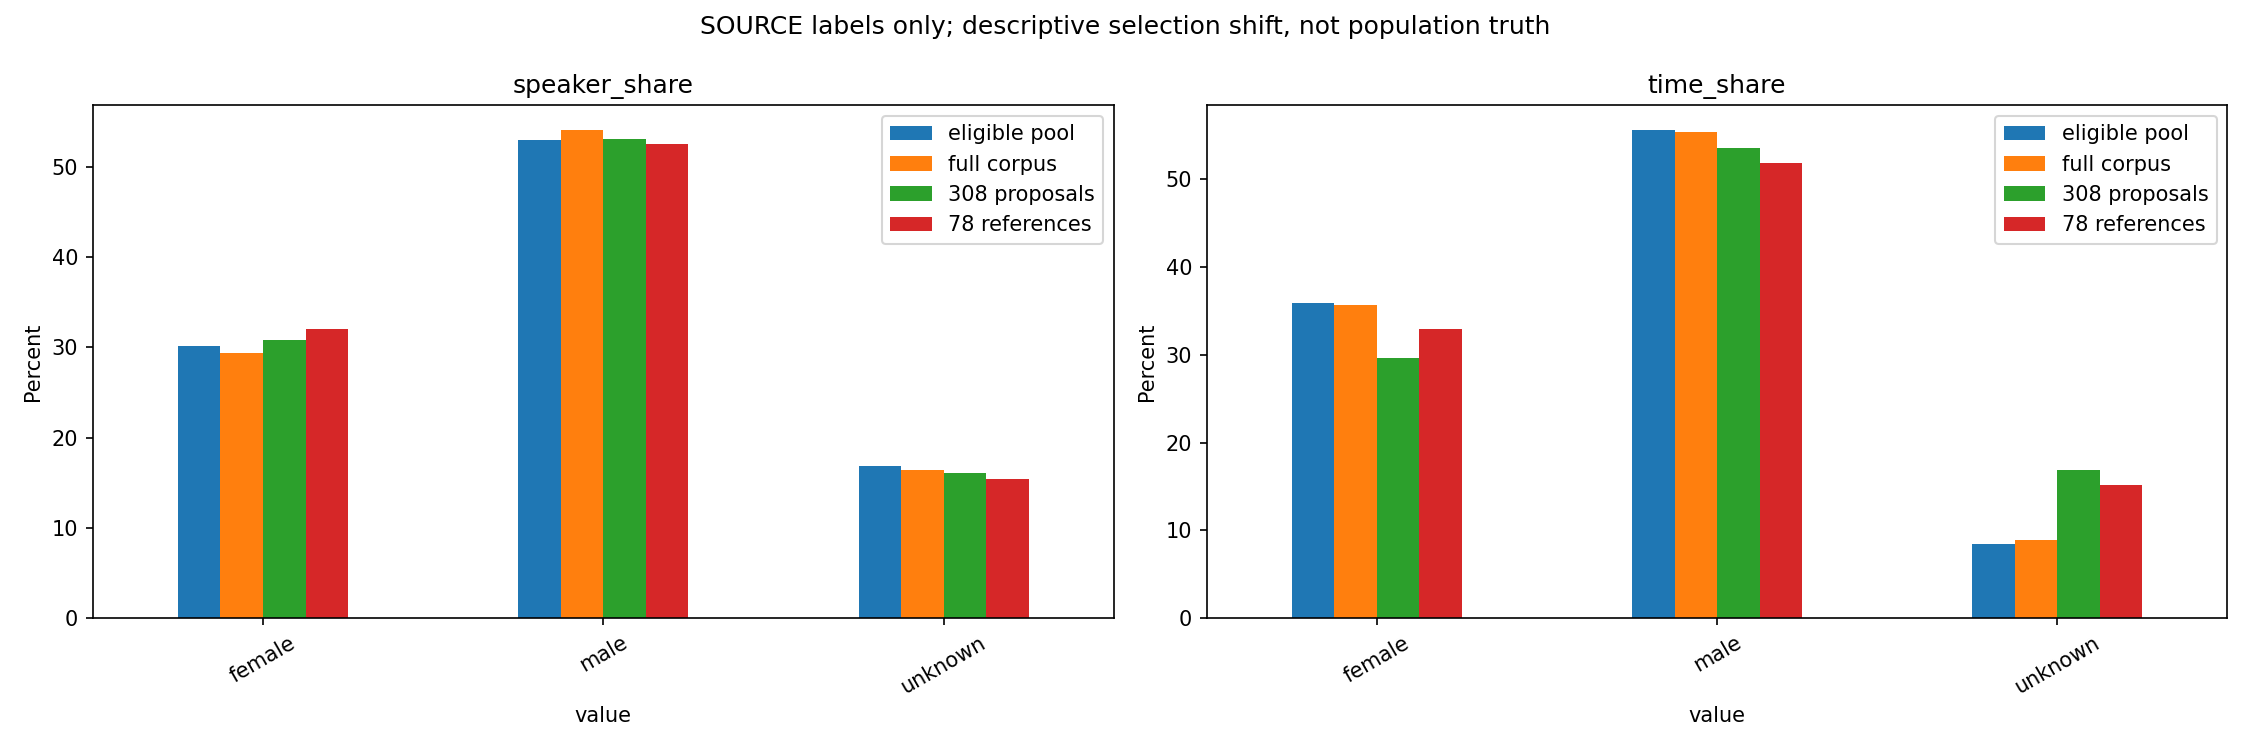

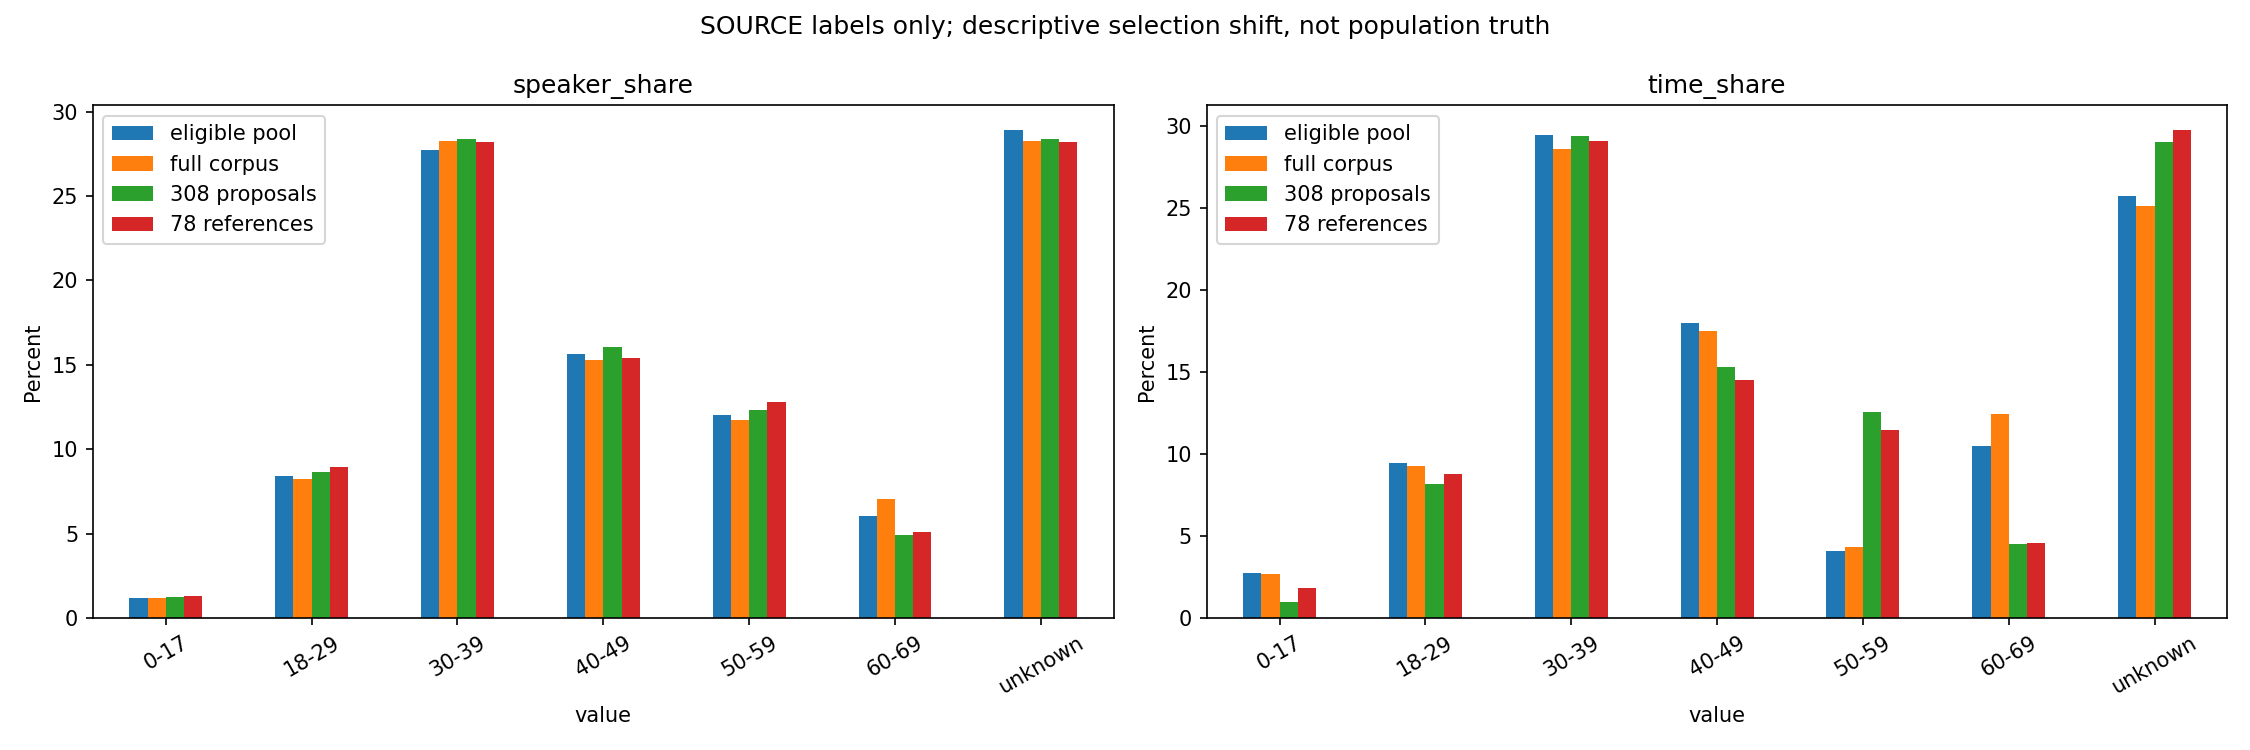

In [5]:
display(table('real_demographic_coverage_by_scope'))
display(table('reference_selection_shift'))
for name in ['source_sex_representation','source_age_representation']:
    display(Image(filename=str(OUT/'figures'/(name+'.png'))))


## 5. Recommended next experiment and verification

Use the current single-sentence synthetic pilot for calibration. Validate proposed real intervals before new generation; assign stock voices within fixed partitions and generate the same text. Balance identity/family exposure, monitor minutes and duration bins, use symmetric boundary/channel processing, and keep controlled and deployment-oriented evaluations separate. Do not force every acoustic feature to match or use detector errors to curate evaluation data.

Concrete priorities and acceptance rules are in `QUALITY_AND_MATCHING_SPEC_HE.md`. Review all seven synthetic outlier candidates and identity coverage before expansion; no human approval is implied by successful automated QC.

Guidance: [ASVspoof 2021](https://www.asvspoof.org/asvspoof2021/asvspoof2021_evaluation_plan.pdf) and [Smeu et al., CVPR 2025](https://openaccess.thecvf.com/content/CVPR2025/papers/Smeu_Circumventing_Shortcuts_in_Audio-visual_Deepfake_Detection_Datasets_with_Unsupervised_Learning_CVPR_2025_paper.pdf). Publication results are not detector results on this corpus.

Reproduce: `python build_quality_audit_notebook.py --execute`, then `python verify_quality_audit.py`.

In [6]:
assert len(real_listen)==85 and real_listen.user_id.is_unique
assert len(synth_listen)==116 and synth_listen.voice_identity_group.is_unique
assert metrics['saved_362_audio_pcm_duplicate_rows']==0
assert metrics['eligible_sixplus_word_cross_speaker_groups']==145
display(json.loads((OUT/'provenance.json').read_text()))
print('Completed offline quality/duplication audit; no source changes or API calls.')


{'inputs': {'eda_outputs\\recording_features.csv': '307d35bfae771956403c21ad83413ff246e6d65b1fc9248cc9dfb57621eb8b15',
  'eda_outputs\\segments.csv': '9efdab84d360093a32eaf91d1856699edf553e0316d3dbffbcf6ceb6762ba44c',
  'eda_outputs\\segment_quality.csv': '3cf7b658aad21143774353706ac028ca6a2d29b24ce624b38d0e3066a51d9f93',
  'synthetic_pilot\\analysis\\sample_features.csv': '20ab4f7a9753af4d5477c4c1f4d94e3c1ea9a7efa8176955bf182d6c3074ac04',
  'synthetic_pilot\\human_reference.csv': '051914777cb1161f9396df04b0abd3bfea024e10723a8880f8779bee2c904b8d',
  'comparison_outputs\\proposed_same_text_pairs.csv': 'f3eaaa25abd4a749e87e25b3772199529069fe58d2a06ebd023dc2476a3c89ee',
  'quality_matching_audit.py': '5ffeb2ad6712c079287f31ae5e6240866a79842fe86b631728f12ee17ff9a062'},
 'normalization': 'lowercase Hebrew/Latin/digits, punctuation removed, whitespace collapsed; diacritics removed',
 'near_text_method': 'all session pairs with >=20 source whitespace words; word unigram/bigram TF-IDF sublinea

Completed offline quality/duplication audit; no source changes or API calls.
